# 01 — Exploratory Data Analysis

## Research and business question

How effectively can network-flow statistics distinguish benign traffic from cyberattacks and separate attack families, and how much can evaluation design overstate that performance?

This core notebook covers data inventory, quality, cleaning, feature engineering, imbalance, outliers, traffic patterns, correlation, class-level distributions, PCA, and an initial CSE-CIC-IDS2018 population inventory. Model fitting is not part of this file. Hypothesis-driven analyses of label ambiguity, testbed shortcuts, near-duplicate leakage, and cross-year distribution drift are separated into [`01_eda_advanced_questions.ipynb`](01_eda_advanced_questions.ipynb).



In [1]:
import glob, os, time, warnings, gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import ks_2samp
from scipy.cluster.hierarchy import linkage, fcluster, dendrogram
from scipy.spatial.distance import squareform
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings('ignore')
pd.set_option('display.width', 200)
pd.set_option('display.max_rows', 120)
pd.set_option('display.max_columns', 40)
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False,
                     'grid.color': '#e6e6e3', 'axes.edgecolor': '#9a9993',
                     'axes.titleweight': 'bold', 'figure.dpi': 100})

BLUE, ORANGE, AQUA, GREY = '#2a78d6', '#eb6834', '#1baf7a', '#9a9993'
SEQ = 'Blues'
PROJECT_ROOT = '.' if os.path.isdir('./Data') else '..'
ROOT = f'{PROJECT_ROOT}/Data/archive'
D17, D18 = f'{ROOT}/CICIDS2017_improved', f'{ROOT}/CSECICIDS2018_improved'
SAMPLE18 = f'{PROJECT_ROOT}/Data/sample_2018_stratified.csv.gz'
SEED = 0
ID_COLS = ['id', 'Flow ID', 'Src IP', 'Src Port', 'Dst IP', 'Timestamp', 'Attempted Category']
ENV_FEATURES = ['Dst Port', 'FWD Init Win Bytes', 'Bwd Init Win Bytes', 'Fwd Seg Size Min', 'Protocol']

def signed_log(a):
    return np.sign(a) * np.log1p(np.abs(a))

/Users/ranga/.matplotlib is not a writable directory


Matplotlib created a temporary cache directory at /var/folders/8p/7ywd43m12fz07p58l3312vqh0000gn/T/matplotlib-l2grdm0e because there was an issue with the default path (/Users/ranga/.matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.



Fontconfig error: No writable cache directories
	/opt/homebrew/var/cache/fontconfig
	/Users/ranga/.cache/fontconfig
	/Users/ranga/.fontconfig


Matplotlib is building the font cache; this may take a moment.


## 1. Files

**Why we are doing this.** Inventorying the source files establishes the physical scope of each dataset before loading it and determines which analyses can run in memory versus in chunks.

**Business relevance.** Knowing that 2018 is much larger than 2017 prevents memory failures and supports a reproducible streaming-and-caching strategy suitable for operational-scale traffic data.


In [2]:
# Get data about CSV files and create a DataFrame with the dataset name, file name, and file size in GB

files = pd.DataFrame([{'dataset': os.path.basename(os.path.dirname(f)), 'file': os.path.basename(f),
                        'size_GB': os.path.getsize(f)/1e9} for d in (D17, D18) for f in sorted(glob.glob(f'{d}/*.csv'))])
display(files.round(3)); files.groupby('dataset').size_GB.agg(['count','sum']).round(2)

,dataset,file,size_GB
0,CICIDS2017_improved,friday.csv,0.285
1,CICIDS2017_improved,monday.csv,0.208
2,CICIDS2017_improved,thursday.csv,0.190
3,CICIDS2017_improved,tuesday.csv,0.178
4,CICIDS2017_improved,wednesday.csv,0.291
5,CSECICIDS2018_improved,Friday-02-03-2018.csv,3.690
6,CSECICIDS2018_improved,Friday-16-02-2018.csv,4.212
7,CSECICIDS2018_improved,Friday-23-02-2018.csv,3.409
8,CSECICIDS2018_improved,Thursday-01-03-2018.csv,3.808
9,CSECICIDS2018_improved,Thursday-15-02-2018.csv,2.993


,count,sum
dataset,,
CICIDS2017_improved,5,1.15
CSECICIDS2018_improved,10,36.04


### Section 1 takeaway

The project contains five CICIDS2017 files and ten CSE-CIC-IDS2018 files. CICIDS2017 can be analyzed in memory, whereas the approximately 36 GB 2018 collection requires chunked scans, cached aggregates, and a stratified analysis sample.


## 2. Columns (identical schema in both datasets)

**Why we are doing this.** The schemas are compared before combining preparation logic or comparing features across years.

**Business relevance.** A shared schema makes a common detector pipeline technically feasible; mismatched definitions would make cross-network performance claims unreliable.


In [3]:
# Get the column names for the 2017 and 2018 datasets and check if they have the same schema

cols17 = pd.read_csv(glob.glob(f'{D17}/*.csv')[0], nrows=5).columns
cols18 = pd.read_csv(glob.glob(f'{D18}/*.csv')[0], nrows=5).columns
print(len(cols17), 'columns; same schema:', list(cols17) == list(cols18))
print(list(cols17))

91 columns; same schema: True
['id', 'Flow ID', 'Src IP', 'Src Port', 'Dst IP', 'Dst Port', 'Protocol', 'Timestamp', 'Flow Duration', 'Total Fwd Packet', 'Total Bwd packets', 'Total Length of Fwd Packet', 'Total Length of Bwd Packet', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Fwd Packet Length Std', 'Bwd Packet Length Max', 'Bwd Packet Length Min', 'Bwd Packet Length Mean', 'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags', 'Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'Fwd RST Flags', 'Bwd RST Flags', 'Fwd Header Length', 'Bwd Header Length', 'Fwd Packets/s', 'Bwd Packets/s', 'Packet Length Min', 'Packet Length Max', 'Packet Length Mean', 'Packet Length Std', 'Packet Length Variance', 'FIN Flag Count', '

### Section 2 takeaway

Both years use the same 91-column schema, so common feature preparation and column-level cross-year comparisons are feasible. Matching names do not guarantee matching distributions, which is tested later.


## 3. Data cleaning and quality checks

**Why we are doing this.** The raw data are checked for missing values, infinite rates, invalid measurements, constants, and duplicate observations before any statistical or model interpretation.

**Business relevance.** A detector trained on corrupted or duplicated records can produce unstable scores, misleading feature importance, and avoidable production failures. Explicit cleaning rules make results auditable.

The raw files are audited before analysis. Missing and infinite values, constant columns, and duplicates are measured explicitly. The EDA retains duplicate rows so their prevalence remains visible; the modeling notebook removes exact feature/label duplicates before splitting.


In [4]:

# Read all CSV files from the 2017 dataset, add a 'day' column based on the file name, and concatenate them into a single DataFrame. Then, perform some basic data exploration and checks.
df = pd.concat([pd.read_csv(f).assign(day=os.path.basename(f)[:-4]) for f in sorted(glob.glob(f'{D17}/*.csv'))], ignore_index=True)


num = df.select_dtypes('number')
print('shape', df.shape, '| memory %.2f GB' % (df.memory_usage().sum()/1e9))
print('non-numeric columns:', list(df.select_dtypes('object').columns))
print('missing values:', df.isna().sum()[lambda s: s>0].to_dict())
print('infinite values:', np.isinf(num).sum()[lambda s: s>0].to_dict())
print('constant columns:', [c for c in num if num[c].nunique() <= 1])
# The following line checks for duplicate rows in the DataFrame, ignoring the specified columns (id, Flow ID, Timestamp, Src Port). 
# It drops these columns and then checks for duplicates in the remaining columns. The sum of duplicated rows is printed.
ids = ['id','Flow ID','Timestamp','Src Port']
print('duplicate rows (ignoring id/flow id/timestamp/src port): %d' % df.drop(columns=ids).duplicated().sum())

shape (2099976, 92) | memory 1.55 GB


non-numeric columns: ['Flow ID', 'Src IP', 'Dst IP', 'Timestamp', 'Label', 'day']


missing values: {}
infinite values: {'Flow Bytes/s': 5, 'Flow Packets/s': 5}


constant columns: []


duplicate rows (ignoring id/flow id/timestamp/src port): 138244


### Cleaning decisions

- The raw files contain no missing cells, so no ordinary missing-value imputation is needed.
- Zero-duration flows create infinite values in `Flow Bytes/s` and `Flow Packets/s`. For modeling, infinity is changed to missing and replaced with the largest finite training value. This preserves the meaning of an extreme rate without allowing infinity into the estimator.
- Duplicate feature/label rows are removed in the modeling notebook. Identifiers and timestamps are excluded from the duplicate key because they can make otherwise identical flows appear unique.
- Constant fields are removed before modeling. Identifier and environment-specific columns are also excluded to reduce testbed leakage.


### Section 3 takeaway

The audit identifies finite-value, invalid-header, constant-feature, and duplicate handling that must occur before modeling. Known measurement anomalies are corrected or isolated, while valid extreme attack behavior is retained.


## 4. Feature engineering

**Why we are doing this.** Raw counters are translated into interpretable measures of total flow size, payload, duration, average packet size, and directional imbalance.

**Business relevance.** Behavioral summaries can help an interpretable Logistic Regression baseline and may transfer better than identifiers or timestamps, but their incremental value must be validated because some duplicate existing columns.

The following variables are derived from raw packet, byte, duration, and timestamp fields. They make flow scale and direction easier to interpret during EDA. Time variables are useful for diagnosing scheduled attack bursts but are excluded from modeling because they would leak the experimental schedule.


### Why these derived features are included

The derived totals, rates, and direction ratio translate raw counters into interpretable flow behavior—overall connection size, duration, average packet size, and communication imbalance. They can be especially useful for a linear Logistic Regression baseline, which cannot easily reconstruct ratios from raw columns, and they may generalize across networks better than environment-specific identifiers such as IP addresses, ports, and timestamps.

These features are not automatically better: some overlap with existing CICIDS columns and can increase multicollinearity. Their value should therefore be validated empirically, ideally by comparing baseline and cross-network performance with and without them. `hour_derived` is retained only for diagnosing scheduled attack bursts and is excluded from model predictors; `is_attack` is the target and must never be used as an input feature.


In [5]:

df['ts'] = pd.to_datetime(df['Timestamp'], errors='coerce')

# mapping the Label column to a binary 'is_attack' column, where attacks are marked as True and benign traffic is marked as False.
# Any lable with pattern ' - Attempted' is also considered benign. 
# Then, several new derived features are created based on existing columns, such as total packets, total payload bytes, duration in seconds, bytes per packet, packet direction ratio, and the hour of the timestamp. 
# Finally, a summary of the engineered features is displayed.
df['is_attack'] = ~df['Label'].eq('BENIGN') & ~df['Label'].str.endswith(' - Attempted')
df['total_packets_derived'] = df['Total Fwd Packet'] + df['Total Bwd packets']
df['total_payload_bytes_derived'] = df['Total Length of Fwd Packet'] + df['Total Length of Bwd Packet']

df['duration_seconds_derived'] = df['Flow Duration'] / 1_000_000 # microseconds to seconds
# Average bytes per packet is calculated by dividing the total payload bytes by the total number of packets
df['bytes_per_packet_derived'] = np.where(
    df['total_packets_derived'] > 0,
    df['total_payload_bytes_derived'] / df['total_packets_derived'],
    np.nan,
)

df['packet_direction_ratio_derived'] = (
    (df['Total Fwd Packet'] + 1) / (df['Total Bwd packets'] + 1)
)
df['hour_derived'] = df['ts'].dt.hour

engineered = [
    'total_packets_derived', 'total_payload_bytes_derived',
    'duration_seconds_derived', 'bytes_per_packet_derived',
    'packet_direction_ratio_derived', 'hour_derived'
]
display(df[engineered].describe(percentiles=[.01, .5, .99]).T.round(3))
num = df.select_dtypes('number')


,count,mean,std,min,1%,50%,99%,max
total_packets_derived,2099976.0,26.729,2027.899,2.000,2.000,4.000,137.000,5.116810e+05
total_payload_bytes_derived,2099976.0,22490.270,2627664.427,0.000,0.000,318.000,105562.000,6.554951e+08
duration_seconds_derived,2099976.0,12.440,31.030,0.000,0.000,0.062,118.104,1.200000e+02
bytes_per_packet_derived,2099976.0,212.022,293.502,0.000,0.000,81.000,1055.909,2.125667e+03
packet_direction_ratio_derived,2099976.0,1.325,4.570,0.022,0.667,1.000,3.000,7.420000e+02
hour_derived,2099976.0,15.540,2.453,11.000,12.000,16.000,19.000,2.000000e+01


### Section 4 takeaway

The engineered variables express flow size, payload, duration, packet size, and direction in analyst-friendly terms. They are useful hypotheses for Logistic Regression and cross-network behavior, but equivalent raw and derived columns should not be retained blindly because they increase redundancy.


## 5. Outlier and anomaly analysis

**Why we are doing this.** Network measurements are highly skewed, so this step separates legitimate extreme behavior from structurally invalid values instead of deleting every statistical outlier.

**Business relevance.** Floods, scans, and slow attacks often occupy distribution tails. Retaining meaningful extremes while correcting invalid rates protects attack recall and data-pipeline reliability.

Network-flow variables are extremely right-skewed. Many statistical outliers are legitimate attacks, such as long slow-DoS connections or very high-rate floods, so outliers are identified and interpreted rather than deleted automatically. The IQR rule below is a screening device, not a removal rule.


,min,p0.1,p1,median,p99,p99.9,max,iqr_outliers,iqr_outlier_share
Flow Duration,0.000,1.000,7.00,61826.000,1.181041e+08,1.198937e+08,1.200000e+08,323663,0.154
Total Fwd Packet,0.000,1.000,1.00,2.000,6.000000e+01,3.520000e+02,2.197590e+05,174984,0.083
Total Bwd packets,0.000,0.000,0.00,2.000,7.500000e+01,5.350250e+02,2.919220e+05,243924,0.116
Total Length of Fwd Packet,0.000,0.000,0.00,80.000,7.018000e+03,3.211015e+04,1.287025e+07,281578,0.134
Total Length of Bwd Packet,0.000,0.000,0.00,218.000,1.015350e+05,9.105894e+05,6.554523e+08,355612,0.169
Flow Bytes/s,0.000,0.000,0.00,3864.201,2.663265e+06,4.505172e+07,2.530000e+08,434836,0.207
Flow Packets/s,0.025,0.031,0.06,73.690,5.000000e+05,2.000000e+06,3.000000e+06,170274,0.081
Packet Length Mean,0.000,0.000,0.00,81.000,1.055909e+03,1.267836e+03,2.125667e+03,340592,0.162


,rows
zero or negative duration,5
negative forward header length,309
negative backward header length,472
infinite flow byte rate,5
infinite flow packet rate,5


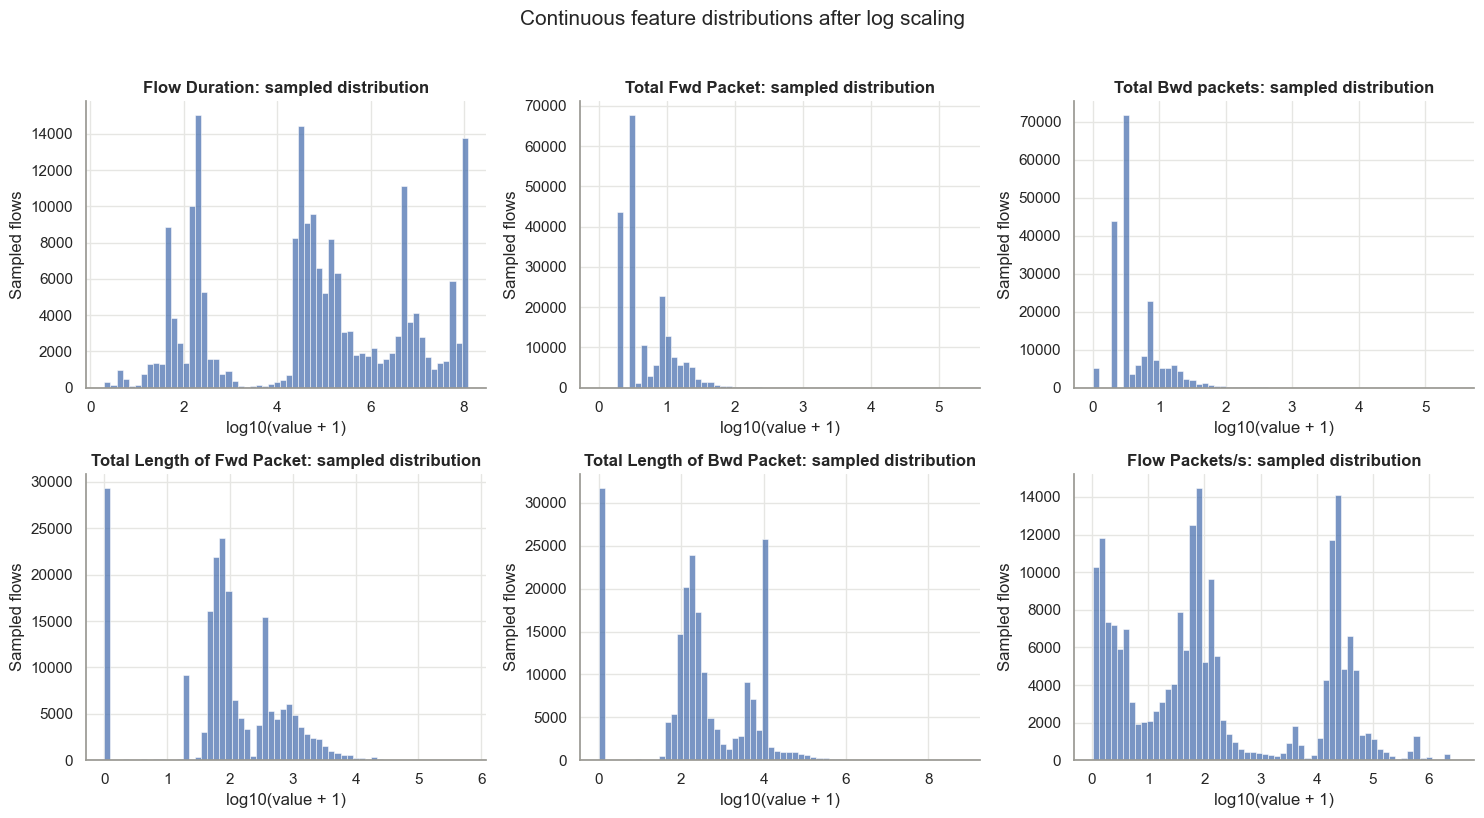

In [6]:
# Identify outlier features and calculate quantiles  

outlier_features = [
    'Flow Duration', 'Total Fwd Packet', 'Total Bwd packets',
    'Total Length of Fwd Packet', 'Total Length of Bwd Packet',
    'Flow Bytes/s', 'Flow Packets/s', 'Packet Length Mean'
]
finite = df[outlier_features].replace([np.inf, -np.inf], np.nan)
quantiles = finite.quantile([0, .001, .01, .5, .99, .999, 1]).T
quantiles.columns = ['min', 'p0.1', 'p1', 'median', 'p99', 'p99.9', 'max']

# Calculate the interquartile range (IQR) and identify outliers based on the IQR method. 
# The number of outliers and their share of the total dataset are added to the quantiles DataFrame, which is then displayed.
q1, q3 = finite.quantile(.25), finite.quantile(.75)
iqr = q3 - q1
iqr_outliers = ((finite.lt(q1 - 1.5 * iqr)) | (finite.gt(q3 + 1.5 * iqr))).sum()
outlier_summary = quantiles.assign(
    iqr_outliers=iqr_outliers,
    iqr_outlier_share=iqr_outliers / len(df)
)
display(outlier_summary.round(3))

anomalies = pd.Series({
    'zero or negative duration': (df['Flow Duration'] <= 0).sum(),
    'negative forward header length': (df['Fwd Header Length'] < 0).sum(),
    'negative backward header length': (df['Bwd Header Length'] < 0).sum(),
    'infinite flow byte rate': np.isinf(df['Flow Bytes/s']).sum(),
    'infinite flow packet rate': np.isinf(df['Flow Packets/s']).sum(),
}, name='rows')
display(anomalies.to_frame())

plot_sample = df.sample(min(200_000, len(df)), random_state=0)
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
plot_features = [
    'Flow Duration', 'Total Fwd Packet', 'Total Bwd packets',
    'Total Length of Fwd Packet', 'Total Length of Bwd Packet',
    'Flow Packets/s'
]
for ax, col in zip(axes.flat, plot_features):
    values = plot_sample[col].replace([np.inf, -np.inf], np.nan).dropna().clip(lower=0)
    sns.histplot(np.log10(values + 1), bins=60, ax=ax, color='#4C72B0')
    ax.set_title(f'{col}: sampled distribution')
    ax.set_xlabel('log10(value + 1)')
    ax.set_ylabel('Sampled flows')
fig.suptitle('Continuous feature distributions after log scaling', fontsize=15, y=1.02)
plt.tight_layout(); plt.show()


In [7]:
num.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
id,2099976.0,218909.82,1.362580e+05,1.00,104999.00,209998.00,314997.00,5.475570e+05
Src Port,2099976.0,48487.23,1.595439e+04,0.00,42757.00,53480.00,60232.00,6.553500e+04
Dst Port,2099976.0,1249.65,5.820510e+03,0.00,53.00,80.00,443.00,6.552900e+04
Protocol,2099976.0,11.23,5.500000e+00,0.00,6.00,6.00,17.00,1.700000e+01
Flow Duration,2099976.0,12440277.46,3.103048e+07,0.00,248.00,61826.00,4388212.75,1.200000e+08
Total Fwd Packet,2099976.0,12.52,8.703800e+02,0.00,2.00,2.00,8.00,2.197590e+05
Total Bwd packets,2099976.0,14.21,1.157980e+03,0.00,2.00,2.00,6.00,2.919220e+05
Total Length of Fwd Packet,2099976.0,570.42,1.046178e+04,0.00,48.00,80.00,358.00,1.287025e+07
Total Length of Bwd Packet,2099976.0,21919.85,2.627459e+06,0.00,100.00,218.00,3881.00,6.554523e+08
Fwd Packet Length Max,2099976.0,210.17,4.917800e+02,0.00,32.00,45.00,310.00,2.482000e+04


### Section 5 takeaway

The log-scaled histograms show that flow duration, packet counts, payload volumes, and packet rates span several orders of magnitude and contain multiple traffic patterns. Most flows are small, but a minority are extremely long, large, or fast. The IQR method consequently flags about 8%–21% of rows for the examined features; these observations should not be deleted automatically because legitimate attacks—such as floods, scans, and slow DoS traffic—can occur in the tails. Instead, the analysis retains statistical extremes and handles clearly invalid measurements, such as infinite rates and negative header lengths, separately before modeling. The plots therefore support using finite-value handling, scaling or transformation, and robust validation rather than indiscriminate outlier removal.


## 6. CICIDS2017: labels and class balance

**Why we are doing this.** Class counts are measured to understand attack prevalence, rare labels, and how the laboratory schedule distributes classes across capture days.

**Business relevance.** Imbalance can make accuracy look strong while rare attacks are missed. It motivates stratified or group-aware evaluation and per-class, macro-averaged metrics.

Labels ending in `- Attempted` are attack attempts with no effective payload (Engelen et al. relabelling).


In [8]:
# Show the share of each label in the dataset. This is important to understand the class distribution and potential class imbalance in the dataset, which can affect model performance and evaluation metrics.
lab17 = df['Label'].value_counts().rename('flows').to_frame()
lab17['share'] = (lab17.flows / lab17.flows.sum()).round(5)
display(lab17)
pd.crosstab(df['Label'], df['day'])

,flows,share
Label,,
BENIGN,1582566,0.75361
Portscan,159066,0.07575
DoS Hulk,158468,0.07546
DDoS,95144,0.04531
Infiltration - Portscan,71767,0.03418
DoS GoldenEye,7567,0.00360
Botnet - Attempted,4067,0.00194
FTP-Patator,3972,0.00189
DoS Slowloris,3859,0.00184


day,friday,monday,thursday,tuesday,wednesday
Label,,,,,
BENIGN,288544,371624,288172,315106,319120
Botnet,736,0,0,0,0
Botnet - Attempted,4067,0,0,0,0
DDoS,95144,0,0,0,0
DoS GoldenEye,0,0,0,0,7567
DoS GoldenEye - Attempted,0,0,0,0,80
DoS Hulk,0,0,0,0,158468
DoS Hulk - Attempted,0,0,0,0,581
DoS Slowhttptest,0,0,0,0,1740


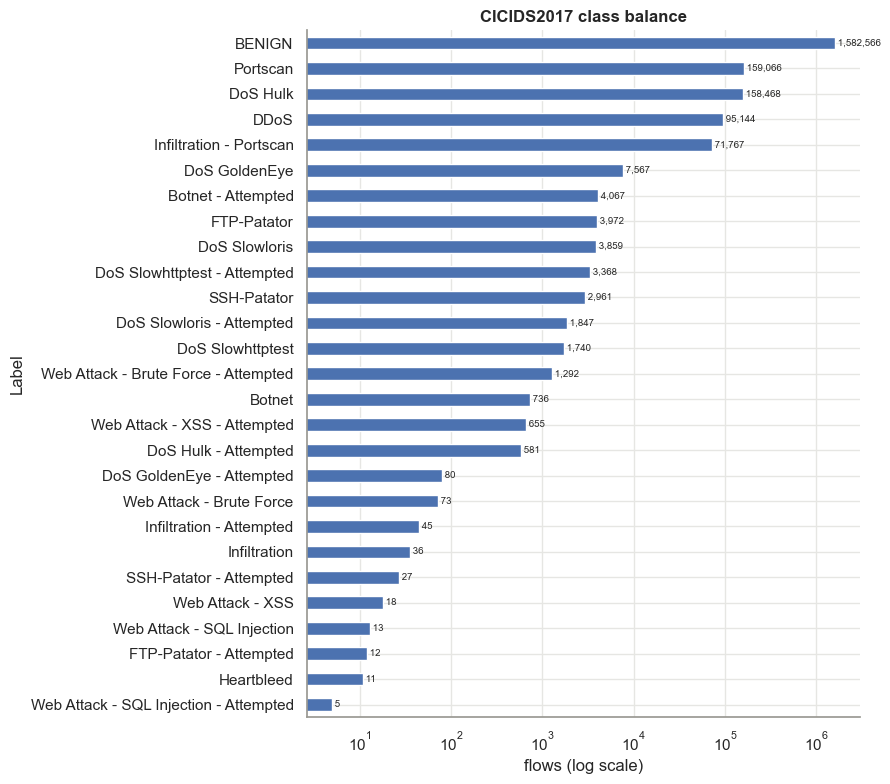

In [9]:
# Show a horizontal bar plot of the number of flows for each label in the CICIDS2017 dataset. The x-axis is on a logarithmic scale to better visualize the differences in flow counts between classes. Each bar is labeled with the exact number of flows for that class.
ax = lab17.flows.plot.barh(figsize=(9,8), logx=True, color='#4C72B0'); ax.invert_yaxis()
ax.set_xlabel('flows (log scale)'); ax.set_title('CICIDS2017 class balance')
for i, v in enumerate(lab17.flows): ax.text(v, i, f' {v:,}', va='center', fontsize=7)
plt.tight_layout(); plt.show()

### Section 6 takeaway

CICIDS2017 is strongly imbalanced: **BENIGN accounts for 75.36% of flows**, while most attack observations are concentrated in Portscan (7.58%), DoS Hulk (7.55%), DDoS (4.53%), and Infiltration–Portscan (3.42%). Several security-relevant classes contain fewer than 100 effective examples, including Heartbleed, Infiltration, and the web attacks, so overall accuracy could look high while the model misses rare attacks. The day table also shows that attack classes are tied to particular capture days, creating a risk that a random split learns the laboratory schedule. Modeling should therefore use stratified or time/group-aware evaluation and report attack recall, precision, F1, and macro-averaged metrics in addition to accuracy; any class weighting or resampling must be applied only to the training data.


## 7. Categorical variables: protocol and destination port

**Why we are doing this.** Protocol and destination-port distributions are compared across benign and attack traffic to identify useful context and possible testbed shortcuts.

**Business relevance.** Ports and protocols can improve detection, but dependence on a laboratory service layout can cause failure in another network. Their value must be tested cross-year.

Protocol 1 = ICMP, 6 = TCP, 17 = UDP, 0 = other / HOPOPT.


In [10]:
# Show a cross-tabulation of the number of flows for each combination of label and protocol in the CICIDS2017 dataset. 
# This helps to understand the distribution of protocols used by different types of traffic (benign and various attack types).
display(pd.crosstab(df['Label'], df['Protocol']))
top_ports = (df.groupby('Label')['Dst Port'].agg(lambda s: ', '.join(f'{p} ({n:,})' for p, n in s.value_counts().head(3).items()))
             .rename('top 3 destination ports (flows)'))
top_ports.to_frame()

Protocol,0,1,6,17
Label,,,,
BENIGN,1508,526,581677,998855
Botnet,0,0,736,0
Botnet - Attempted,0,0,4067,0
DDoS,0,0,95144,0
DoS GoldenEye,0,0,7567,0
DoS GoldenEye - Attempted,0,0,80,0
DoS Hulk,0,0,158468,0
DoS Hulk - Attempted,0,0,581,0
DoS Slowhttptest,0,0,1740,0


,top 3 destination ports (flows)
Label,
BENIGN,"53 (957,755), 443 (389,958), 80 (165,940)"
Botnet,8080 (736)
Botnet - Attempted,"8080 (4,067)"
DDoS,"80 (95,144)"
DoS GoldenEye,"80 (7,567)"
DoS GoldenEye - Attempted,80 (80)
DoS Hulk,"80 (158,468)"
DoS Hulk - Attempted,80 (581)
DoS Slowhttptest,"80 (1,740)"


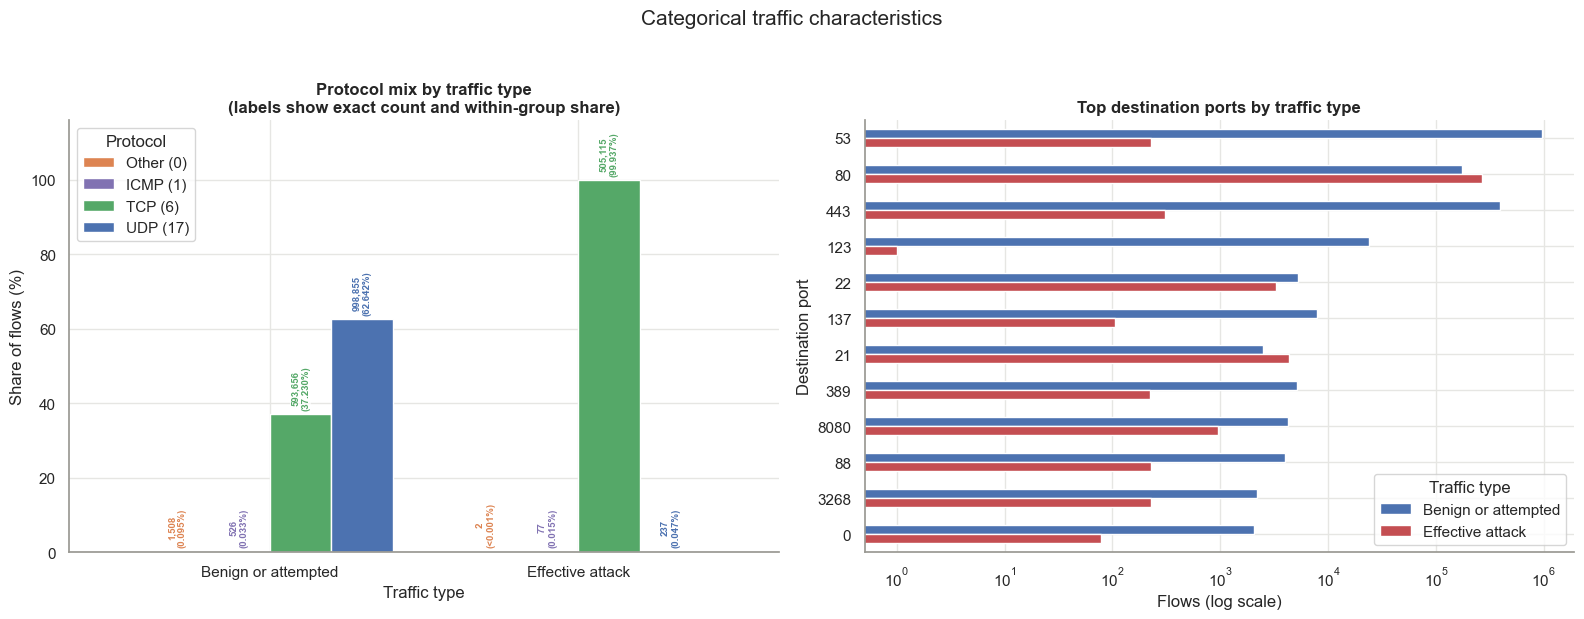

In [11]:
traffic = np.where(df['is_attack'], 'Effective attack', 'Benign or attempted')
protocol_names = {0: 'Other (0)', 1: 'ICMP (1)', 6: 'TCP (6)', 17: 'UDP (17)'}
protocol_colors = {
    'Other (0)': '#DD8452',
    'ICMP (1)': '#8172B2',
    'TCP (6)': '#55A868',
    'UDP (17)': '#4C72B0',
}

# Keep both exact counts and row-normalized percentages. The counts are used in
# labels so rare protocols remain visible even when their bars are too small to see.
protocol_counts = (pd.crosstab(pd.Series(traffic, name='Traffic type'), df['Protocol'])
                     .rename(columns=protocol_names))
protocol_plot = protocol_counts.div(protocol_counts.sum(axis=1), axis=0) * 100

top_port_ids = df['Dst Port'].value_counts().head(12).index
port_plot = (pd.crosstab(pd.Series(traffic, name='Traffic type'), df['Dst Port'])
               .reindex(columns=top_port_ids, fill_value=0).T)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
protocol_plot.plot.bar(
    ax=axes[0],
    color=[protocol_colors[column] for column in protocol_plot.columns],
    width=0.8,
)

# Annotate every nonzero protocol bar with exact count and percentage. Labels for
# very small bars are lifted above the baseline rather than hidden by the scale.
for column, container in zip(protocol_plot.columns, axes[0].containers):
    for row_number, bar in enumerate(container):
        count = int(protocol_counts.iloc[row_number][column])
        percentage = float(protocol_plot.iloc[row_number][column])
        if count == 0:
            continue
        percentage_text = '<0.001%' if percentage < 0.001 else f'{percentage:.3f}%'
        label_y = percentage + 1 if percentage >= 1 else 1.5
        axes[0].text(
            bar.get_x() + bar.get_width() / 2,
            label_y,
            f'{count:,}\n({percentage_text})',
            ha='center', va='bottom', rotation=90,
            fontsize=7, fontweight='bold', color=protocol_colors[column],
            bbox=dict(facecolor='white', edgecolor='none', alpha=0.72, pad=0.6),
            clip_on=False,
        )

axes[0].set_ylim(0, 116)
axes[0].set_title('Protocol mix by traffic type\n(labels show exact count and within-group share)')
axes[0].set_xlabel('Traffic type'); axes[0].set_ylabel('Share of flows (%)')
axes[0].tick_params(axis='x', rotation=0); axes[0].legend(title='Protocol', loc='upper left')

port_plot.plot.barh(ax=axes[1], color=['#4C72B0', '#C44E52'])
axes[1].invert_yaxis(); axes[1].set_xscale('log')
axes[1].set_title('Top destination ports by traffic type')
axes[1].set_xlabel('Flows (log scale)'); axes[1].set_ylabel('Destination port')
axes[1].legend(title='Traffic type')
fig.suptitle('Categorical traffic characteristics', fontsize=15, y=1.03)
plt.tight_layout(); plt.show()

### Section 7 takeaway

Protocol and destination port strongly characterize this laboratory dataset. Effective attacks are almost entirely TCP—505,115 flows, or 99.937%—although 316 ICMP, UDP, or other-protocol attack flows show that attacks are not exclusively TCP. Benign or attempted traffic is dominated by UDP and TCP, while destination ports align closely with the generated scenarios: benign traffic frequently uses ports 53, 443, and 80, and many attack classes target a single service such as HTTP (80), SSH (22), FTP (21), or 8080. These variables may help detection within CICIDS2017, but they can also encode the lab's service layout. Protocol and port should therefore be treated as contextual signals—not proof of maliciousness—and their usefulness must be confirmed through cross-network evaluation.


## 8. CICIDS2017: attack timing

**Why we are doing this.** Traffic is plotted over capture time to reveal scheduled attack bursts and dependence among neighboring flows.

**Business relevance.** Randomly splitting one burst between training and testing can overstate future detection ability. Timing analysis supports event-aware, chronological, and cross-network evaluation.

Flows per 10 minutes for each day, benign vs attack. Attacks come in scheduled bursts, so a random split will mix flows from the same burst into train and test.


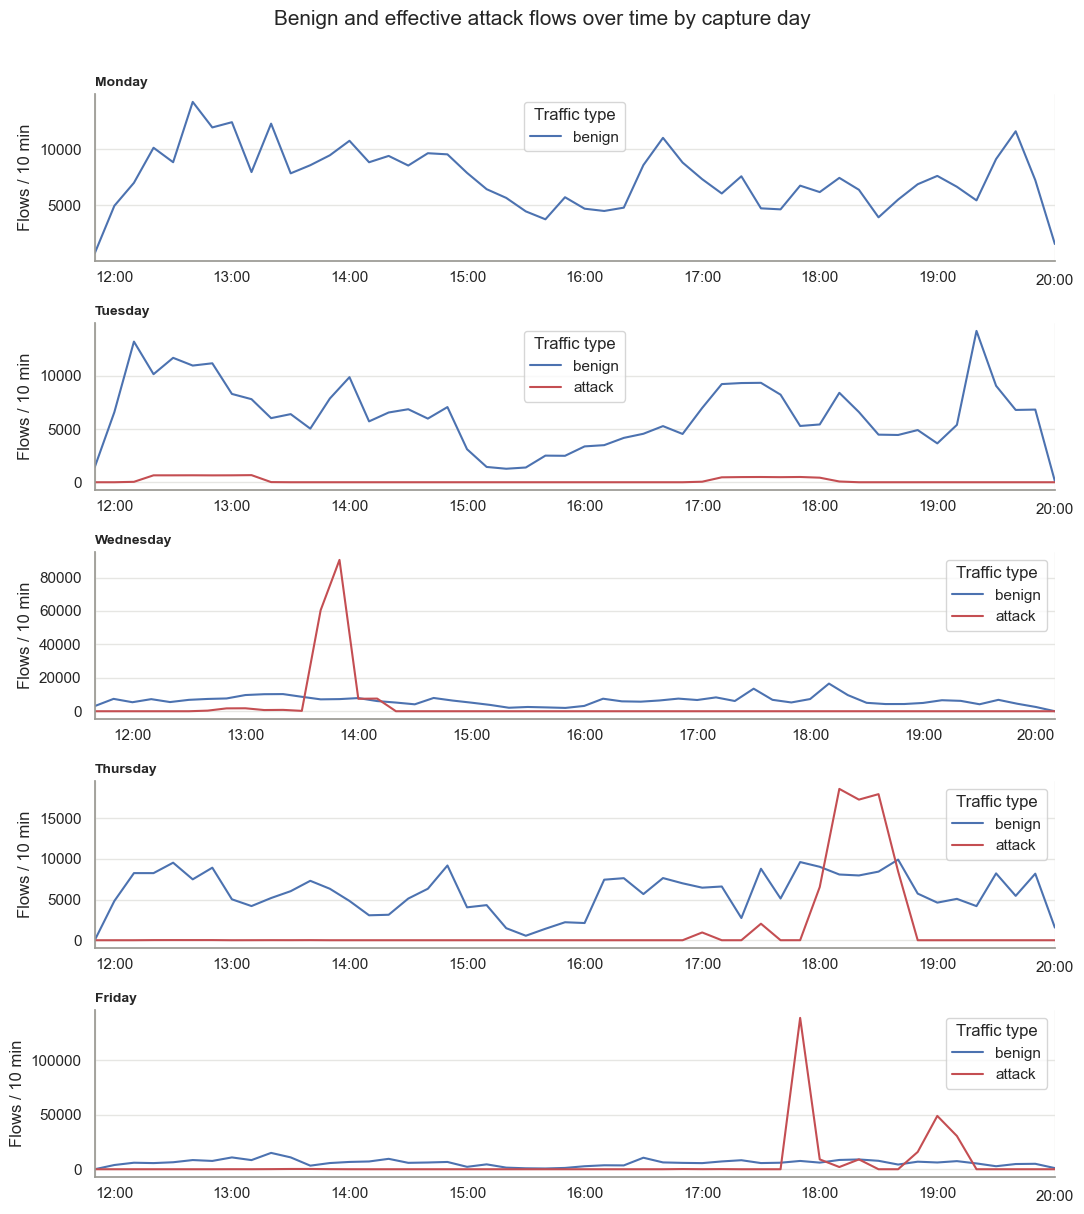

min                        max   count
day       Label                                                                                   
friday    Botnet                     2017-07-07 13:04:13.990571 2017-07-07 14:02:02.808963     736
          DDoS                       2017-07-07 18:56:31.796937 2017-07-07 19:16:10.645771   95144
          Portscan                   2017-07-07 16:55:32.117090 2017-07-07 18:23:53.256235  159066
thursday  Infiltration               2017-07-06 17:19:02.547210 2017-07-06 18:44:24.375292      36
          Infiltration - Portscan    2017-07-06 17:00:31.706755 2017-07-06 18:46:04.331747   71767
          Web Attack - Brute Force   2017-07-06 12:19:27.660566 2017-07-06 12:59:41.197757      73
          Web Attack - SQL Injection 2017-07-06 13:35:45.732950 2017-07-06 13:42:50.310628      13
          Web Attack - XSS           2017-07-06 13:16:16.603214 2017-07-06 13:34:28.136241      18
tuesday   FTP-Patator                2017-07-04 12:19:20.152476 2017-07-04 13:20:13.627945    3972
          SSH-Patator                2017-07-04 17:09:01.049616 2017-07-04 19:04:15.353690    2961
wednesday DoS GoldenEye              2017-07-05 14:10:03.231753 2017-07-05 14:19:49.515445    7567
          DoS Hulk                   2017-07-05 13:43:23.194704 2017-07-05 14:01:34.512067  158468
          DoS Slowhttptest           2017-07-05 13:15:37.936810 2017-07-05 13:35:18.764958    1740
          DoS Slowloris              2017-07-05 12:48:54.539220 2017-07-05 13:10:11.354291    3859
          Heartbleed                 2017-07-05 18:12:15.650811 2017-07-05 18:32:18.242051      11

In [12]:
# SHow BENIGN AND EFFECTIVE ATTACK over time by capture day. 
# This visualization helps to understand the temporal distribution of benign and attack flows across different days of the week. 
# Each subplot represents a day, showing the number of flows (benign and attack) aggregated over 10-minute intervals.
days = ['monday','tuesday','wednesday','thursday','friday']
fig, axes = plt.subplots(len(days), 1, figsize=(11, 12))
for ax, d in zip(axes, days):
    t = df[df.day == d].set_index('ts').groupby('is_attack').resample('10min').size().unstack(0, fill_value=0)
    t.rename(columns={False: 'benign', True: 'attack'}).plot(ax=ax, color={'benign': '#4C72B0', 'attack': '#C44E52'})
    ax.set_title(d.title(), loc='left', fontsize=10); ax.set_xlabel(''); ax.set_ylabel('Flows / 10 min')
    ax.legend(title='Traffic type')
fig.suptitle('Benign and effective attack flows over time by capture day', fontsize=15, y=1.01)
plt.tight_layout(); plt.show()
(df[df.is_attack].groupby(['day','Label']).ts.agg(['min','max','count']))


### Section 8 takeaway: why attack timing matters

The timing analysis checks whether the evaluation could benefit from the dataset's scheduled attack windows rather than genuine attack generalization. For example, all **158,468 DoS Hulk flows** were generated during one approximately 18-minute period on Wednesday (about 13:43–14:01). With a random 80/20 split, roughly 126,000 flows from this event could enter training and 32,000 highly related flows from the same event could enter testing. A high score would then show that the model recognizes more flows from the same burst, not necessarily a future DoS attack.

This risk remains even when timestamp is removed because neighboring flows can share ports, packet rates, window settings, and other event-specific characteristics. Therefore, `Timestamp`, `day`, and `hour_derived` are excluded from predictors, and random-split results should be supplemented with time- or event-aware evaluation. The project's cross-year test—training on CICIDS2017 and testing on CSE-CIC-IDS2018—provides the strongest evidence that the detector generalizes beyond a single laboratory schedule.


## 9. Feature relationships and multicollinearity

**Why we are doing this.** This analysis identifies which numeric features have the strongest linear association with effective attack status and which predictors contain nearly duplicate information. It is computed on a reproducible 200,000-row sample of numeric flow features after excluding identifier and leakage-prone columns. Correlation is used as an exploratory screening tool; it does not prove causation or that a feature will generalize to another network.

**Business relevance.** A compact, less-redundant feature set is faster to calculate in a production detector, easier for security analysts to explain, and less likely to produce unstable Logistic Regression coefficients. It also makes laboratory shortcuts—such as protocol or duplicated testbed measurements—easier to identify before deployment. Features should be retained based on validation and cross-network performance, not correlation alone.


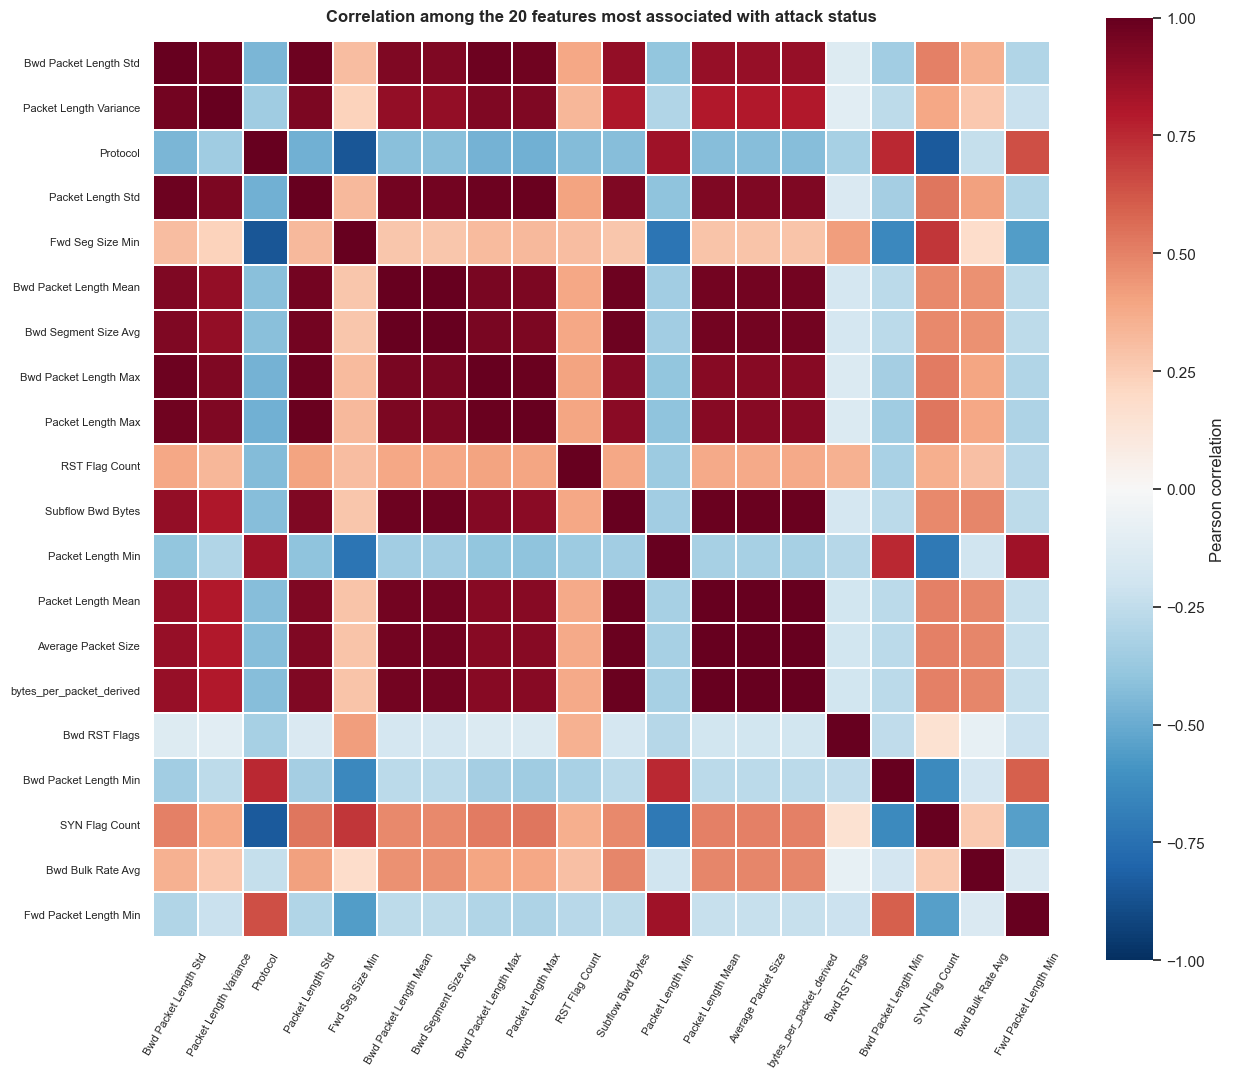

88 features with variance; 72 pairs with |r| > 0.95


,correlation with attack
Bwd Packet Length Std,0.550520
Packet Length Variance,0.544704
Protocol,-0.535611
Packet Length Std,0.534664
Fwd Seg Size Min,0.528339
Bwd Segment Size Avg,0.525974
Bwd Packet Length Mean,0.525974
Bwd Packet Length Max,0.525592
Packet Length Max,0.513598
RST Flag Count,0.486517


pairwise correlation
Flow Duration              duration_seconds_derived                 1.000000
Packet Length Mean         bytes_per_packet_derived                 1.000000
                           Average Packet Size                      1.000000
Fwd URG Flags              URG Flag Count                           1.000000
Fwd Packet Length Mean     Fwd Segment Size Avg                     1.000000
Average Packet Size        bytes_per_packet_derived                 1.000000
Bwd Packet Length Mean     Bwd Segment Size Avg                     1.000000
Total Length of Bwd Packet total_payload_bytes_derived              0.999999
ACK Flag Count             total_packets_derived                    0.999982
Total Bwd packets          total_packets_derived                    0.999741
                           ACK Flag Count                           0.999721
Total Fwd Packet           total_packets_derived                    0.999563
                           ACK Flag Count                           0.999548
Flow Duration              Fwd IAT Total                            0.999449
Fwd IAT Total              duration_seconds_derived                 0.999449
Total Fwd Packet           Total Bwd packets                        0.998631
Flow IAT Max               Fwd IAT Max                              0.998489
                           Idle Max                                 0.998294
Fwd IAT Max                Idle Max                                 0.996784
Total Fwd Packet           total_payload_bytes_derived              0.994384
                           Total Length of Bwd Packet               0.994376
Bwd Bytes/Bulk Avg         Bwd Packet/Bulk Avg                      0.991400
total_packets_derived      total_payload_bytes_derived              0.991078
ACK Flag Count             total_payload_bytes_derived              0.991073
Total Length of Bwd Packet total_packets_derived                    0.991069
                           ACK Flag Count                           0.991065
Bwd Packet Length Max      Packet Length Max                        0.990182
Idle Mean                  Idle Min                                 0.989840
Packet Length Max          Packet Length Std                        0.988526
Total Bwd packets          total_payload_bytes_derived              0.987945

In [13]:

ids = ['id', 'Src Port', 'Attempted Category', 'hour_derived']
feat = num.drop(columns=[c for c in ids if c in num]).replace([np.inf, -np.inf], np.nan)
feat = feat.loc[:, feat.nunique() > 1]
sample_idx = feat.sample(min(200_000, len(feat)), random_state=0).index
sample_features = feat.loc[sample_idx]
sample_target = df.loc[sample_idx, 'is_attack'].astype(int)

attack_corr = sample_features.corrwith(sample_target).dropna()
top_features = attack_corr.abs().nlargest(20).index
focused_corr = sample_features[top_features].corr()

fig, ax = plt.subplots(figsize=(13, 11))
sns.heatmap(focused_corr, cmap='RdBu_r', center=0, vmin=-1, vmax=1,
            square=True, linewidths=.25, cbar_kws={'label': 'Pearson correlation'}, ax=ax)
ax.set_title('Correlation among the 20 features most associated with attack status', pad=14)
ax.tick_params(axis='x', labelrotation=60, labelsize=8)
ax.tick_params(axis='y', labelrotation=0, labelsize=8)
plt.tight_layout(); plt.show()

all_corr = sample_features.corr()
upper = all_corr.where(np.triu(np.ones(all_corr.shape, dtype=bool), 1)).stack()
high = upper[upper.abs() > 0.95].sort_values(key=abs, ascending=False)
print(f'{len(feat.columns)} features with variance; {len(high)} pairs with |r| > 0.95')
display(attack_corr.sort_values(key=abs, ascending=False).head(20).rename('correlation with attack').to_frame())
display(high.rename('pairwise correlation').to_frame().head(30))


### Section 9 takeaway

The sample contains 88 varying numeric features, but 72 feature pairs have an absolute Pearson correlation above 0.95, showing substantial redundancy. Several engineered or dataset-provided variables are effectively equivalent—for example, `Flow Duration` and `duration_seconds_derived`, and `Packet Length Mean`, `Average Packet Size`, and `bytes_per_packet_derived`. The strongest individual attack associations are moderate rather than definitive (`Bwd Packet Length Std` is approximately 0.55), so no single feature proves that a flow is malicious. Before Logistic Regression modeling, redundant groups should be reduced or controlled with regularization to improve coefficient stability and interpretability. Features such as `Protocol` also require cross-network validation because their correlation may reflect the CICIDS laboratory configuration rather than durable attack behavior.


## 10. Continuous variables by class

**Why we are doing this.** Section 9 measures overall feature correlation with binary attack status; this section checks whether selected flow behaviors differ for specific attack classes. Log-scaled box plots compare duration, packet counts, packet size, timing, rate, and TCP-window variables using up to 5,000 flows per class. Attempted labels are folded into `BENIGN`, consistent with the baseline target. The per-class sample makes rare classes visible and is not intended to reproduce population proportions.

**Business relevance.** A useful detector must recognize multiple attack behaviors rather than only the largest attack class. These comparisons show which features may help identify floods, scans, slow DoS, or infiltration and where benign and malicious traffic overlap. They also expose environment-sensitive variables—particularly TCP initial-window values—that may perform well in the CICIDS laboratory but fail on another network. The results guide feature selection, per-class evaluation, and cross-network validation.


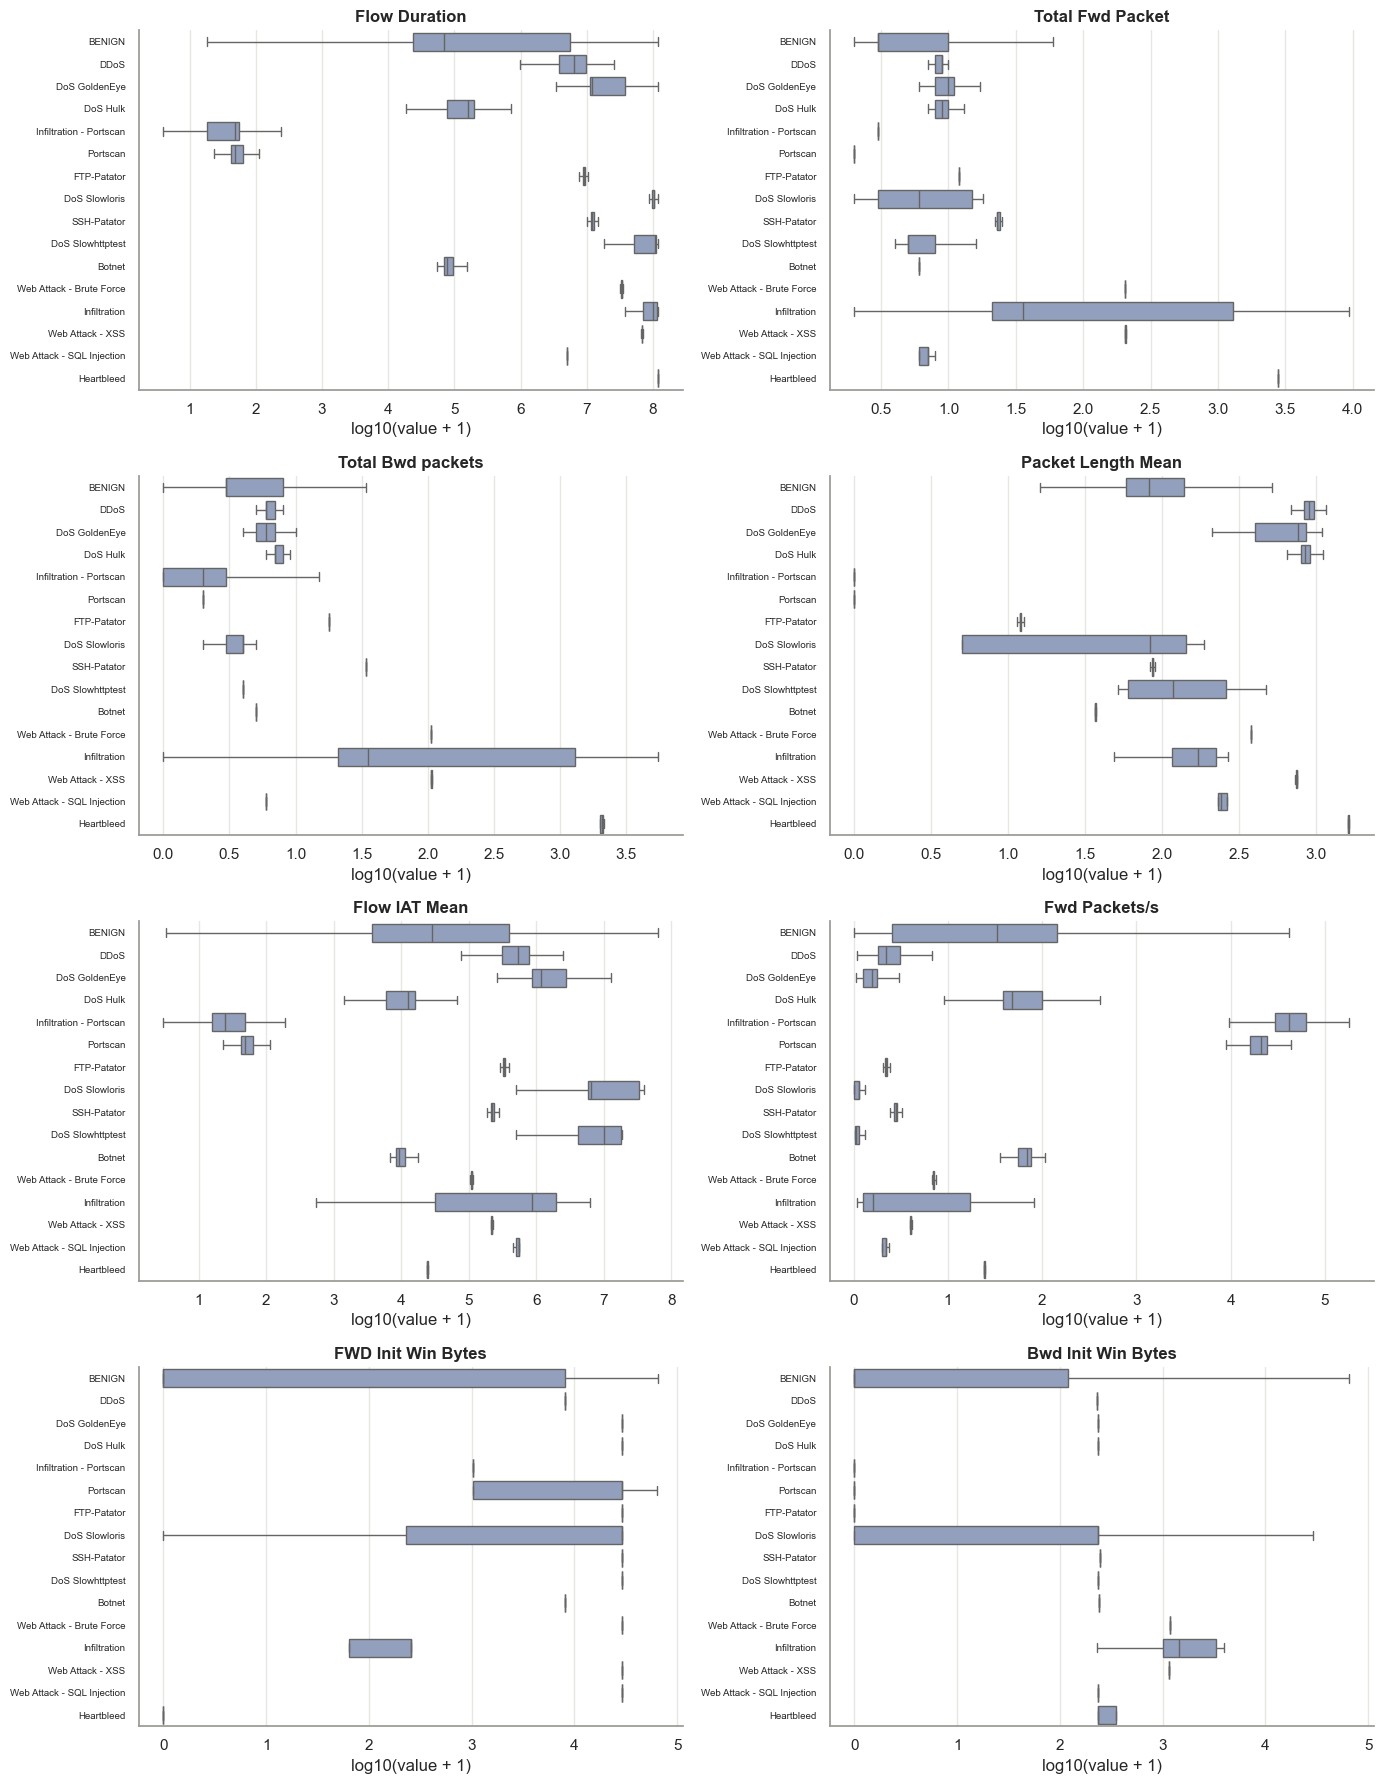

In [14]:
df['y'] = df['Label'].where(~df['Label'].str.endswith(' - Attempted'), 'BENIGN')
samp = df.groupby('y', group_keys=False).apply(lambda g: g.sample(min(len(g), 5000), random_state=0))
order = samp['y'].value_counts().index
show = ['Flow Duration', 'Total Fwd Packet', 'Total Bwd packets', 'Packet Length Mean',
        'Flow IAT Mean', 'Fwd Packets/s', 'FWD Init Win Bytes', 'Bwd Init Win Bytes']
fig, axes = plt.subplots(4, 2, figsize=(14, 18))
for ax, c in zip(axes.flat, show):
    sns.boxplot(data=samp.assign(v=np.log10(samp[c].clip(lower=0) + 1)), y='y', x='v', order=order,
                showfliers=False, ax=ax, color='#8C9DC4')
    ax.set_title(c); ax.set_xlabel('log10(value + 1)'); ax.set_ylabel('')
    ax.tick_params(axis='y', labelsize=7)
plt.tight_layout(); plt.show()

### Section 10 takeaway

The class distributions confirm that attacks do not share one universal signature. Port-scanning traffic tends to have short flows, few responses, small packets, and high forward packet rates, while Slowloris and Slowhttptest show long durations, larger inter-arrival times, and low rates. Flood and DoS classes have distinct packet-size, volume, and rate combinations, and no single feature cleanly separates every class from benign traffic. This supports a multivariate detector and per-class precision, recall, and F1 reporting. TCP initial-window fields provide strong apparent separation for some classes but may encode operating-system, tool, or testbed configuration; their real value must therefore be confirmed in the CICIDS2017-to-2018 evaluation.


## 11. Class separability with PCA

**Why we are doing this.** Sections 9 and 10 examine correlations and one feature at a time; PCA provides a two-dimensional view of the combined numeric feature space. After finite-value handling, signed-log transformation, and standardization, PCA projects the same per-class sample onto two synthetic axes. PCA is unsupervised—the labels are used only to color the points after projection—so visible class clusters indicate naturally different multivariate flow profiles rather than separation explicitly optimized from the labels.

**Business relevance.** The plot helps assess whether automated detection is plausible when many flow measurements are considered together and identifies overlapping regions where false positives or missed attacks may occur. It can also reveal compact, tool-specific clusters that may be laboratory fingerprints. PCA is therefore an exploratory diagnostic, not a performance metric; supervised evaluation and CICIDS2017-to-2018 testing are still required before claiming that the patterns generalize.


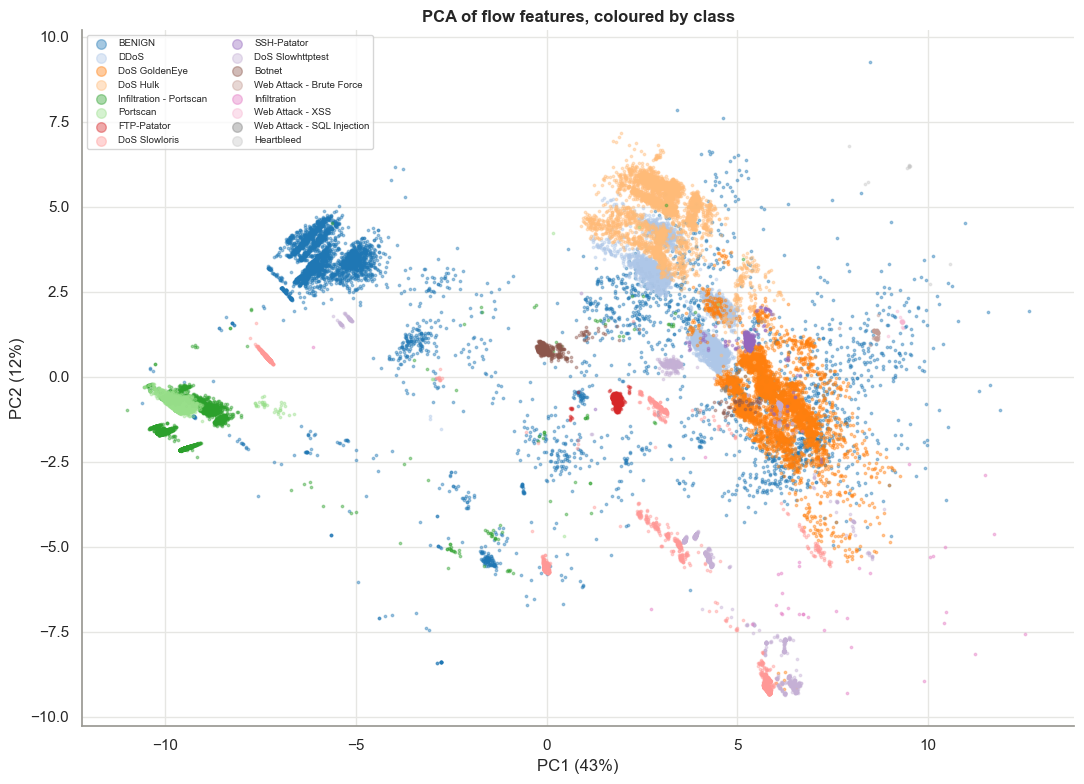

In [15]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
F = samp[feat.columns].replace([np.inf, -np.inf], np.nan).fillna(0)
Z = StandardScaler().fit_transform(np.sign(F) * np.log1p(np.abs(F)))
pc = PCA(2, random_state=0).fit(Z); P = pc.transform(Z)
fig, ax = plt.subplots(figsize=(11, 8))
pal = sns.color_palette('tab20', len(order))
for c, col in zip(order, pal):
    m = (samp['y'] == c).values
    ax.scatter(P[m, 0], P[m, 1], s=3, alpha=0.4, color=col, label=c)
ax.set_xlabel(f'PC1 ({pc.explained_variance_ratio_[0]:.0%})'); ax.set_ylabel(f'PC2 ({pc.explained_variance_ratio_[1]:.0%})')
ax.legend(markerscale=4, fontsize=7, ncol=2); ax.set_title('PCA of flow features, coloured by class'); plt.tight_layout(); plt.show()
del feat, samp, F, Z, P

### Section 11 takeaway

The first two principal components explain approximately **55% of transformed-feature variation** (PC1: 43%; PC2: 12%). Some attacks, particularly port-scanning and several tool-generated classes, occupy concentrated regions, showing that combinations of features contain useful class structure. However, benign traffic is widely distributed and several attack classes overlap with benign traffic or with one another, so two dimensions do not provide complete separation. The result supports multivariate modeling but does not establish classifier accuracy or cross-network robustness: 45% of the variation is outside the plot, and apparently distinct clusters may reflect attack tools, operating systems, ports, or other CICIDS laboratory characteristics. Final conclusions must come from per-class model metrics and cross-year evaluation.


## 12. CSE-CIC-IDS2018: labels and class balance (streamed)

**Why we are doing this.** The complete 2018 label population is counted by streaming all files, providing exact prevalence without loading approximately 36 GB into memory.

**Business relevance.** Exact class counts establish the external-test environment, expose imbalance and label differences, and prevent a stratified sample from being mistaken for production prevalence.


In [16]:
RESULTS_DIR = f'{PROJECT_ROOT}/EDA/results'
os.makedirs(RESULTS_DIR, exist_ok=True)
CACHE = f'{RESULTS_DIR}/label_counts_2018.csv'
if os.path.exists(CACHE):
    lc18 = pd.read_csv(CACHE)
else:
    parts = []
    for f in sorted(glob.glob(f'{D18}/*.csv')):
        for ch in pd.read_csv(f, usecols=['Label'], chunksize=2_000_000):
            parts.append(ch['Label'].value_counts().rename_axis('Label').reset_index(name='flows').assign(file=os.path.basename(f)))
    lc18 = pd.concat(parts).groupby(['file','Label'], as_index=False).flows.sum()
    lc18.to_csv(CACHE, index=False)
lab18 = lc18.groupby('Label').flows.sum().sort_values(ascending=False).to_frame()
lab18['share'] = (lab18.flows / lab18.flows.sum()).round(5)
print('total flows: %s' % f'{lab18.flows.sum():,}'); display(lab18)
lc18.pivot(index='Label', columns='file', values='flows').fillna(0).astype(int)

total flows: 63,195,145


,flows,share
Label,,
BENIGN,59353486,0.93921
DoS Hulk,1803160,0.02853
DDoS-HOIC,1082293,0.01713
FTP-BruteForce - Attempted,298874,0.00473
DDoS-LOIC-HTTP,289328,0.00458
Botnet Ares,142921,0.00226
SSH-BruteForce,94197,0.00149
Infiltration - NMAP Portscan,89374,0.00141
DoS GoldenEye,22560,0.00036


file,Friday-02-03-2018.csv,Friday-16-02-2018.csv,Friday-23-02-2018.csv,Thursday-01-03-2018.csv,Thursday-15-02-2018.csv,Thursday-22-02-2018.csv,Tuesday-20-02-2018.csv,Wednesday-14-02-2018.csv,Wednesday-21-02-2018.csv,Wednesday-28-02-2018.csv
Label,,,,,,,,,,
BENIGN,6168188,5481500,5976251,6511554,5372471,6070945,5764497,5610799,5878399,6518882
Botnet Ares,142921,0,0,0,0,0,0,0,0,0
Botnet Ares - Attempted,262,0,0,0,0,0,0,0,0,0
DDoS-HOIC,0,0,0,0,0,0,0,0,1082293,0
DDoS-LOIC-HTTP,0,0,0,0,0,0,289328,0,0,0
DDoS-LOIC-UDP,0,0,0,0,0,0,797,0,1730,0
DDoS-LOIC-UDP - Attempted,0,0,0,0,0,0,80,0,171,0
DoS GoldenEye,0,0,0,0,22560,0,0,0,0,0
DoS GoldenEye - Attempted,0,0,0,0,4301,0,0,0,0,0


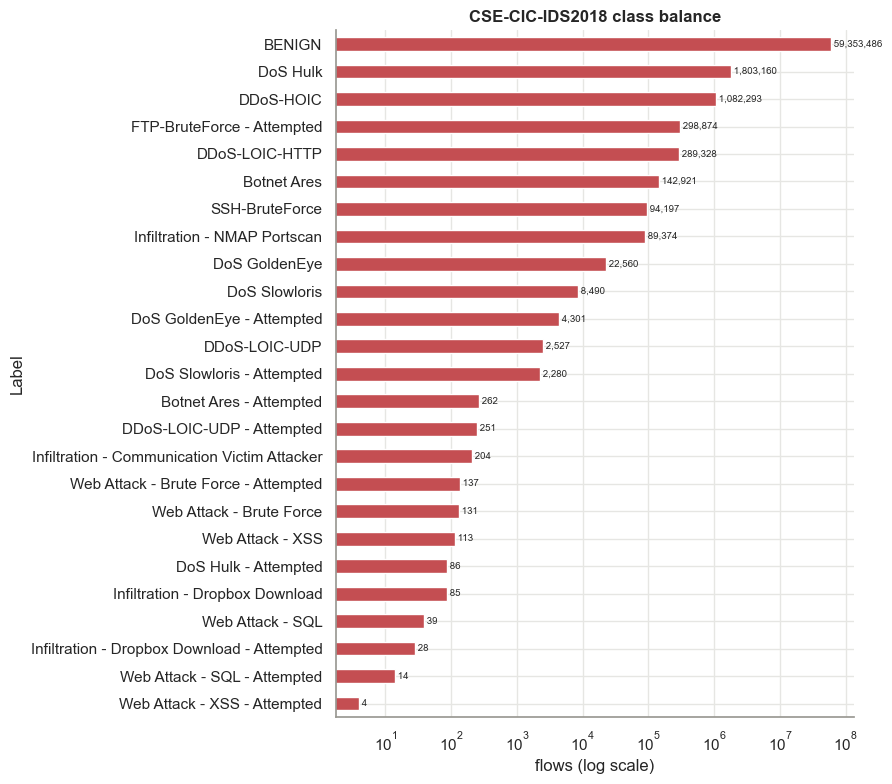

In [17]:
ax = lab18.flows.plot.barh(figsize=(9,8), logx=True, color='#C44E52'); ax.invert_yaxis()
ax.set_xlabel('flows (log scale)'); ax.set_title('CSE-CIC-IDS2018 class balance')
for i, v in enumerate(lab18.flows): ax.text(v, i, f' {v:,}', va='center', fontsize=7)
plt.tight_layout(); plt.show()

### Section 12 takeaway

The exact streamed population shows that CSE-CIC-IDS2018 is strongly benign-dominated and contains a different label mix from 2017. These exact counts—not the balanced analysis sample—must be used when describing prevalence and external-test conditions.


## Consolidated EDA conclusions and business implications

Detailed evidence for attempted-label ambiguity, feature separation, redundancy clustering, testbed shortcuts, split leakage, and cross-year drift is provided in [`01_eda_advanced_questions.ipynb`](01_eda_advanced_questions.ipynb).

- Network-flow statistics contain strong signals for detecting attacks, but the dataset is severely imbalanced and several attack classes have very few examples. Macro F1 is therefore more informative than accuracy.
- Infinite rate values, constants, duplicates, and leakage-prone identifiers require explicit handling. Statistical outliers are retained because extreme behavior is often the attack signal.
- Scheduled bursts and near-duplicate flows make random train/test splits optimistic. Within-class chronological evaluation is more representative of future traffic.
- The 83 model features form only 37 correlation groups at |ρ| ≥ 0.9, supporting a future reduced-feature experiment.
- A single feature separates most attack classes, and environment-specific fields such as destination port and TCP window sizes are often sufficient. High within-lab scores may therefore reflect testbed recognition rather than attack behavior.
- Shared attack families drift substantially between 2017 and 2018, particularly in timing and server-response features. Cross-year model evaluation is required before making deployment claims.
- Attempted attacks are neither conventionally benign nor equivalent to effective attacks. The baseline policy folds them into benign traffic, but future work should compare dropping them or modeling them separately.

These findings define the baseline modeling workflow: exclude identifiers and schedule fields, use signed-log standardization for Logistic Regression, report macro F1, compare random and chronological splits, and include a cross-year detection check.

## EDA roadmap findings and statistics

The following table is generated programmatically from the analysis objects created above. Rerunning the notebook after changing the source data, cleaning policy, or sample will automatically update the reported statistics.


In [18]:
# Programmatic core-EDA summary: all statistics are derived from notebook variables.
def pct(value):
    return f'{100 * value:.2f}%'

file_counts = files.groupby('dataset').size()
file_sizes = files.groupby('dataset')['size_GB'].sum()
label_counts17 = lab17['flows']
raw_rows = int(label_counts17.sum())
effective_mask17 = (df['Label'] != 'BENIGN') & ~df['Label'].str.endswith(' - Attempted')

derived_packets = df['Total Fwd Packet'] + df['Total Bwd packets']
derived_payload = df['Total Length of Fwd Packet'] + df['Total Length of Bwd Packet']
derived_seconds = df['Flow Duration'] / 1_000_000
derived_bpp = derived_payload / derived_packets.replace(0, np.nan)
derived_ratio = (df['Total Fwd Packet'] + 1) / (df['Total Bwd packets'] + 1)

attack_windows = df[effective_mask17].groupby('Label').ts.agg(['min', 'max', 'count'])
attack_windows['minutes'] = (attack_windows['max'] - attack_windows['min']).dt.total_seconds() / 60
largest_burst = attack_windows.sort_values('count', ascending=False).iloc[0]

duplicate_count = int(df.drop(columns=['id', 'Flow ID', 'Timestamp', 'Src Port']).duplicated().sum())
varying_features = int(num.nunique().gt(1).sum())

roadmap_findings = pd.DataFrame([
    (1, 'Source-file inventory',
     f"{int(file_counts.get('CICIDS2017_improved', 0))} CICIDS2017 files ({file_sizes.get('CICIDS2017_improved', 0):.2f} GB) and "
     f"{int(file_counts.get('CSECICIDS2018_improved', 0))} CSE-CIC-IDS2018 files ({file_sizes.get('CSECICIDS2018_improved', 0):.2f} GB).",
     'Use full-memory analysis for 2017 and streaming/caching for 2018.'),
    (2, 'Schema compatibility',
     f'{len(cols17)} columns; schemas match: {list(cols17) == list(cols18)}.',
     'A common preparation pipeline and feature-level cross-year comparison are feasible.'),
    (3, 'Data-quality audit',
     f'{raw_rows:,} CICIDS2017 rows; {int(anomalies["infinite flow byte rate"])} infinite byte-rate and '
     f'{int(anomalies["infinite flow packet rate"])} infinite packet-rate rows; {duplicate_count:,} model-aligned duplicates.',
     'Invalid finite values and duplicates require explicit handling before modeling.'),
    (4, 'Feature engineering',
     f'Medians: {derived_packets.median():.0f} packets, {derived_payload.median():.0f} payload bytes, '
     f'{derived_seconds.median():.3f} seconds, {derived_bpp.median():.1f} bytes/packet, '
     f'{derived_ratio.median():.2f} direction ratio.',
     'Derived values express flow size, duration, and direction in analyst-friendly terms.'),
    (5, 'Outliers and anomalies',
     f'IQR outlier shares range from {pct(outlier_summary.iqr_outlier_share.min())} to '
     f'{pct(outlier_summary.iqr_outlier_share.max())}; '
     f'{int(anomalies["negative forward header length"])} negative forward and '
     f'{int(anomalies["negative backward header length"])} negative backward headers.',
     'Retain valid extremes that may be attacks; isolate known measurement anomalies.'),
    (6, 'Label balance',
     f'CICIDS2017 benign share {pct(label_counts17.loc["BENIGN"] / label_counts17.sum())}; '
     f'CSE-CIC-IDS2018 benign share {pct(lab18.loc["BENIGN", "share"])}; '
     f'{int(effective_mask17.sum()):,} effective 2017 attack flows.',
     'Use macro F1 and per-class measures because benign traffic and common attacks dominate.'),
    (7, 'Protocol and port analysis',
     f'{int((df.loc[effective_mask17, "Protocol"] == 6).sum()):,} of '
     f'{int(effective_mask17.sum()):,} effective-attack flows use TCP; '
     f'{df.loc[effective_mask17, "Dst Port"].nunique()} attack destination ports appear.',
     'Ports and protocols are context but may encode the laboratory service layout.'),
    (8, 'Attack timing',
     f'Largest class burst: {largest_burst.name} with {int(largest_burst["count"]):,} flows across '
     f'{largest_burst["minutes"]:.1f} minutes.',
     'Scheduled bursts make random splitting vulnerable to temporal leakage.'),
    (9, 'Correlation analysis',
     f'{len(high)} exploratory feature pairs have |Pearson r| > 0.95; '
     f'maximum absolute attack-status correlation is {attack_corr.abs().max():.3f}.',
     'Correlated columns divide signal and complicate coefficient interpretation.'),
    (10, 'Class-level distributions',
     f'{df.y.nunique()} traffic classes; support ranges from '
     f'{df.y.value_counts().min():,} to {df.y.value_counts().max():,} flows.',
     'Common attacks support stable distributions; rare classes require cautious conclusions.'),
    (11, 'PCA visualization',
     f'First two components explain {pct(pc.explained_variance_ratio_.sum())} of transformed-feature variance.',
     'Two dimensions reveal broad structure but cannot fully represent class separation.'),
    (12, '2018 population inventory',
     f'{int(lab18.flows.sum()):,} flows across {len(lab18)} labels; '
     f'BENIGN represents {pct(lab18.loc["BENIGN", "share"])}.',
     'Use exact streamed counts for prevalence; detailed 2018 EDA remains in its companion notebook.'),
], columns=['Step', 'Analysis', 'Finding and supporting statistics', 'Implication'])

display(roadmap_findings.style.hide(axis='index').set_properties(**{
    'text-align': 'left', 'white-space': 'normal'
}).set_table_styles([
    {'selector': 'th', 'props': [('text-align', 'left')]},
    {'selector': 'td:nth-child(1)', 'props': [('width', '45px')]},
    {'selector': 'td:nth-child(2)', 'props': [('width', '180px')]},
]))

print(
    f'Core EDA: {raw_rows:,} CICIDS2017 flows and {int(lab18.flows.sum()):,} CSE-CIC-IDS2018 flows were inventoried. '
    f'Advanced questions about target ambiguity, shortcuts, leakage, and cross-year drift are documented in '
    f'01_eda_advanced_questions.ipynb.'
)

Step,Analysis,Finding and supporting statistics,Implication
1,Source-file inventory,5 CICIDS2017 files (1.15 GB) and 10 CSE-CIC-IDS2018 files (36.04 GB).,Use full-memory analysis for 2017 and streaming/caching for 2018.
2,Schema compatibility,91 columns; schemas match: True.,A common preparation pipeline and feature-level cross-year comparison are feasible.
3,Data-quality audit,"2,099,976 CICIDS2017 rows; 5 infinite byte-rate and 5 infinite packet-rate rows; 2 model-aligned duplicates.",Invalid finite values and duplicates require explicit handling before modeling.
4,Feature engineering,"Medians: 4 packets, 318 payload bytes, 0.062 seconds, 81.0 bytes/packet, 1.00 direction ratio.","Derived values express flow size, duration, and direction in analyst-friendly terms."
5,Outliers and anomalies,IQR outlier shares range from 8.11% to 20.71%; 309 negative forward and 472 negative backward headers.,Retain valid extremes that may be attacks; isolate known measurement anomalies.
6,Label balance,"CICIDS2017 benign share 75.36%; CSE-CIC-IDS2018 benign share 93.92%; 505,431 effective 2017 attack flows.",Use macro F1 and per-class measures because benign traffic and common attacks dominate.
7,Protocol and port analysis,"505,115 of 505,431 effective-attack flows use TCP; 1103 attack destination ports appear.",Ports and protocols are context but may encode the laboratory service layout.
8,Attack timing,"Largest class burst: Portscan with 159,066 flows across 88.4 minutes.",Scheduled bursts make random splitting vulnerable to temporal leakage.
9,Correlation analysis,72 exploratory feature pairs have |Pearson r| > 0.95; maximum absolute attack-status correlation is 0.551.,Correlated columns divide signal and complicate coefficient interpretation.
10,Class-level distributions,"16 traffic classes; support ranges from 11 to 1,594,545 flows.",Common attacks support stable distributions; rare classes require cautious conclusions.


Core EDA: 2,099,976 CICIDS2017 flows and 63,195,145 CSE-CIC-IDS2018 flows were inventoried. Advanced questions about target ambiguity, shortcuts, leakage, and cross-year drift are documented in 01_eda_advanced_questions.ipynb.
